In [ ]:
from ast import increment_lineno
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
import io
import pandas as pd

csv_data = """CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
1,Female,39,60,55
2,Male,34,96,92
3,Male,39,53,59
4,Male,18,128,16
5,Female,35,75,72
6,Female,42,38,96
7,Female,57,33,37
8,Male,31,72,79
9,Male,27,54,51
10,Male,31,77,83
11,Female,49,71,88
12,Male,42,58,56
13,Male,31,38,85
14,Female,44,22,14
15,Female,39,48,41
16,Female,34,51,55
17,Female,24,79,15
18,Female,20,53,49
19,Male,29,78,39
20,Female,19,55,59
21,Male,35,84,33
22,Female,35,46,55
23,Female,21,39,64
24,Male,28,49,58
25,Female,31,54,55
26,Male,31,71,32
27,Male,21,118,29
28,Female,33,70,55
29,Female,34,52,50
30,Male,34,52,43
31,Female,24,37,84
32,Male,57,118,34
33,Male,39,45,55
34,Female,21,36,88
35,Female,35,51,59
36,Male,41,54,58
37,Female,32,71,31
38,Male,40,40,51
39,Female,41,61,50
40,Male,37,100,75
41,Female,37,60,53
42,Female,52,66,42
43,Female,38,59,48
44,Female,30,68,54
45,Female,31,43,51
46,Male,32,60,53
47,Male,34,56,41
48,Female,20,48,51
49,Female,37,70,51
50,Female,30,59,57
51,Female,34,68,43
52,Female,42,67,49
53,Female,32,58,58
54,Male,42,47,40
55,Female,29,54,58
56,Female,39,52,55
57,Female,26,44,57
58,Female,50,60,56
59,Female,27,51,46
60,Female,35,55,59
61,Female,39,46,47
62,Female,38,71,35
63,Female,32,61,53
64,Female,26,52,43
65,Female,31,52,46
66,Female,35,63,55
67,Female,41,66,54
68,Male,29,53,44
69,Female,34,50,42
70,Female,38,70,41
71,Female,31,45,51
72,Male,35,57,59
73,Male,34,70,43
74,Male,19,101,23
75,Female,24,66,53
76,Male,27,61,54
77,Female,26,67,52
78,Male,38,62,49
79,Female,42,63,52
80,Female,41,52,49
81,Male,34,113,87
82,Male,27,63,55
83,Male,44,54,49
84,Male,47,60,40
85,Male,37,60,50
86,Male,42,61,43
87,Female,31,64,57
88,Female,45,56,49
89,Female,42,43,59
90,Female,38,59,53
91,Female,41,60,54
92,Male,19,43,45
93,Female,45,61,45
94,Male,38,47,49
95,Female,42,51,43
96,Female,25,72,13
97,Male,39,59,48
98,Female,41,51,57
99,Male,38,61,45
100,Male,39,55,47"""

df = pd.read_csv(io.StringIO(csv_data))
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Female,39,60,55
1,2,Male,34,96,92
2,3,Male,39,53,59
3,4,Male,18,128,16
4,5,Female,35,75,72


In [ ]:
from sklearn.preprocessing import StandardScaler

# Selecting the correct features for clustering
x = df[['Annual Income (k$)', 'Spending Score (1-100)']]
x.head()

,Annual Income (k$),Spending Score (1-100)
0,60,55
1,96,92
2,53,59
3,128,16
4,75,72


In [ ]:
scalar=StandardScaler()
x_scaled=scalar.fit_transform(x)
x_scaled

array([[-0.03001164,  0.22328928],
       [ 2.0085147 ,  2.61798589],
       [-0.42639176,  0.4821754 ],
       [ 3.82053811, -2.30085039],
       [ 0.81937434,  1.32355529],
       [-1.27577773,  2.87687201],
       [-1.55890639, -0.94169826],
       [ 0.64949714,  1.776606  ],
       [-0.36976603, -0.03559684],
       [ 0.9326258 ,  2.03549212],
       [ 0.59287141,  2.35909977],
       [-0.1432631 ,  0.28801081],
       [-1.27577773,  2.16493518],
       [-2.18178944, -2.43029345],
       [-0.70952042, -0.68281214],
       [-0.53964322,  0.22328928],
       [ 1.04587726, -2.36557192],
       [-0.42639176, -0.1650399 ],
       [ 0.98925153, -0.8122552 ],
       [-0.3131403 ,  0.4821754 ],
       [ 1.32900592, -1.20058438],
       [-0.82277188,  0.22328928],
       [-1.219152  ,  0.80578305],
       [-0.65289469,  0.41745387],
       [-0.36976603,  0.22328928],
       [ 0.59287141, -1.26530591],
       [ 3.2542808 , -1.4594705 ],
       [ 0.53624568,  0.22328928],
       [-0.48301749,

In [ ]:
# find best k (elbow method)
print("finding best k")
inertia = []
sil_scores = []
k_values = range(2, 11)
for k in k_values:
  kmeans = KMeans(n_clusters=k, random_state=42)
  kmeans.fit(x_scaled)
  inertia.append(kmeans.inertia_)
  sil_scores.append(silhouette_score(x_scaled, kmeans.labels_))

finding best k


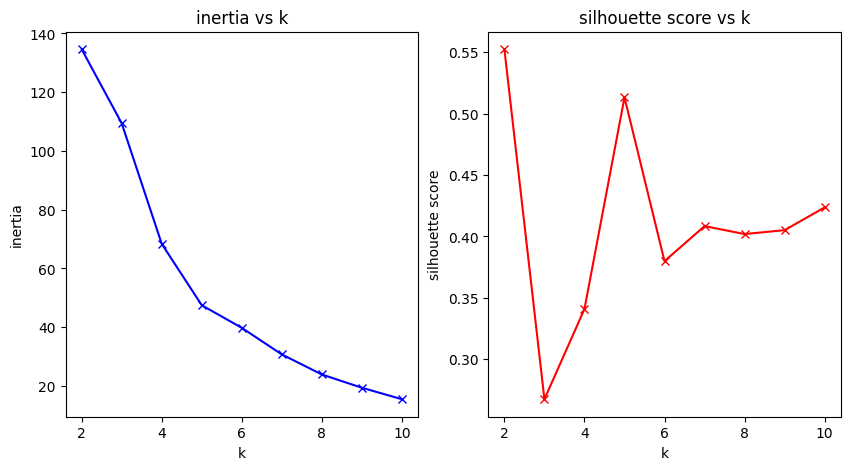

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(k_values, inertia, 'bx-')
plt.xlabel('k')
plt.ylabel('inertia')
plt.title('inertia vs k')
plt.subplot(1,2,2)
plt.plot(k_values, sil_scores, 'rx-')
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.title('silhouette score vs k')
plt.show()

In [ ]:
best_k = k_values[np.argmax(sil_scores)]
print('best k is', best_k)

best k is 2


In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=42, max_iter=10)
kmeans.fit(x_scaled)
print(f"\ncluster centers:\n{kmeans.cluster_centers_}")
print(f"silhouette score: {silhouette_score(x_scaled, kmeans.labels_)}")


cluster centers:
[[-0.30781082  0.13572486]
 [ 1.74426129 -0.76910751]]
silhouette score: 0.5524095836909427


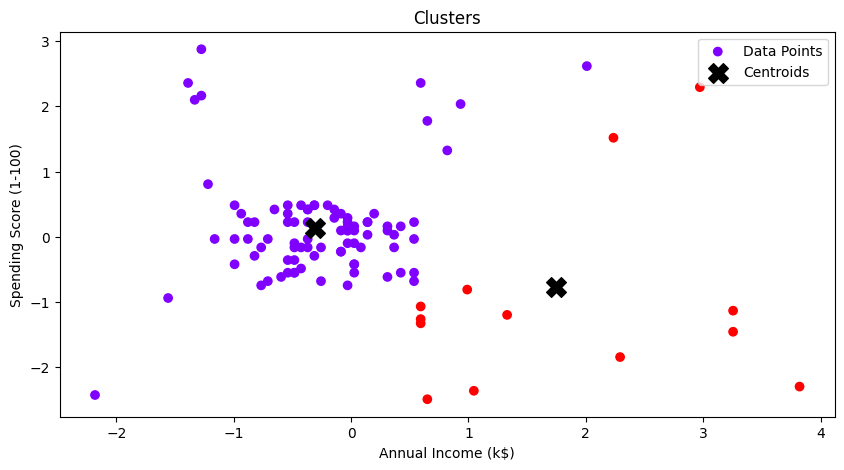

In [ ]:
plt.figure(figsize=(10,5))
plt.scatter(x_scaled[:,0], x_scaled[:,1], c=kmeans.labels_, cmap='rainbow', label='Data Points')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], color='black', marker='X', s=200, label='Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Clusters')
plt.legend()
plt.show()

In [ ]:
df['cluster'] = kmeans.labels_
print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1  Female   39                  60                      55   
1           2    Male   34                  96                      92   
2           3    Male   39                  53                      59   
3           4    Male   18                 128                      16   
4           5  Female   35                  75                      72   

   cluster  
0        0  
1        0  
2        0  
3        1  
4        0  
